# Рівень 1. Класифікація ASCII-арту класичними методами ML

**Задача:** за ASCII-рисунком визначити, який об'єкт на ньому зображено (10 класів).
**Напрямок:** B — зображення.
**Метод рівня 1:** ручне вилучення ознак (структурні ознаки, частоти символів, HOG) + класичні класифікатори (Logistic Regression, SVM, Random Forest).

План ноутбука:
1. Завантаження і огляд датасету
2. Рендер ASCII-арту в зображення
3. Розбиття на train / validation / test
4. Ручні ознаки
5. Вимірювання часу і пам'яті
6. Підбір моделі на validation
7. Внесок кожної групи ознак
8. Фінальна оцінка на test
9. Зведення результатів
10. Висновки

## 1. Датасет

Датасет зібраний власноруч із сайтів [asciiart.website](https://asciiart.website) та [asciiart.eu](https://www.asciiart.eu).

- кожен рисунок — окремий `.txt` файл у папці свого класу (`dataset/cat/`, `dataset/boat/`, ...);
- `manifest.csv` — розмітка: клас, шлях до файлу, джерело, розміри рисунка;
- `rejected.csv` — рисунки, відкинуті під час збору: занадто малі (1–2 рядки, з них неможливо зрозуміти об'єкт) та майже-дублікати.

Видалення дублікатів важливе для чесної оцінки: якщо один і той самий рисунок потрапить і в train, і в test, модель «впізнає» його, а не розпізнає, і метрика буде завищеною.

In [1]:
import json
import os
import string
import threading
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from PIL import Image, ImageDraw, ImageFont
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
DATASET_DIR = '../dataset'
SPLITS_PATH = '../splits.csv'
IMAGE_SIZE = 128

In [2]:
manifest = pd.read_csv(os.path.join(DATASET_DIR, 'manifest.csv'))
texts = [open(os.path.join(DATASET_DIR, f), encoding='utf-8').read() for f in manifest['file']]
labels = manifest['label'].to_numpy()
classes = sorted(manifest['label'].unique())

print(f'Рисунків: {len(texts)}, класів: {len(classes)}')
manifest[['label', 'file', 'site', 'height', 'width', 'chars']].head()

Рисунків: 1341, класів: 10


,label,file,site,height,width,chars
0,airplane,airplane/eu_0001.txt,eu,3,13,34
1,airplane,airplane/eu_0002.txt,eu,3,14,39
2,airplane,airplane/eu_0003.txt,eu,3,19,50
3,airplane,airplane/eu_0004.txt,eu,2,29,56
4,airplane,airplane/eu_0005.txt,eu,4,35,131


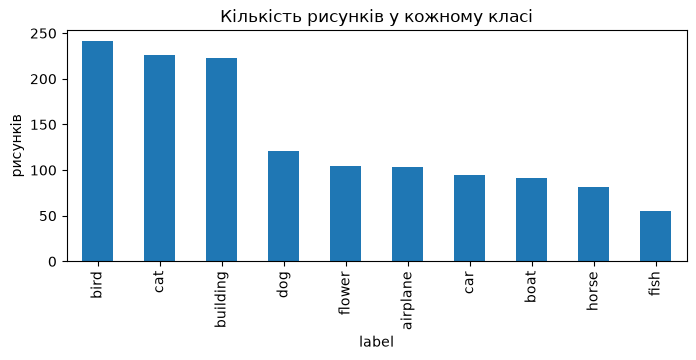

label,bird,cat,building,dog,flower,airplane,car,boat,horse,fish
рисунків,241,226,223,121,104,103,95,91,82,55


In [3]:
counts = manifest['label'].value_counts()
counts.plot.bar(figsize=(8, 3), title='Кількість рисунків у кожному класі')
plt.ylabel('рисунків')
plt.show()
counts.to_frame('рисунків').T

Класи **незбалансовані**: найбільший клас (bird) майже в 4.5 раза більший за найменший (fish). Це впливає на три рішення далі:
- розбиття робимо **стратифікованим**, щоб у кожній частині була однакова частка кожного класу;
- моделям вмикаємо `class_weight='balanced'` — помилки на рідкісних класах штрафуються сильніше;
- основна метрика — **macro-F1**, а не accuracy: вона рахує F1 для кожного класу окремо і усереднює, тому провал на малому класі одразу видно.

## 2. Рендер ASCII-арту в зображення

ASCII-арт — це текст, але його зміст візуальний: важливо, як символи розташовані один відносно одного у 2D. Тому кожен рисунок перетворюємо на зображення:

1. малюємо текст моноширинним шрифтом (DejaVu Sans Mono — він вбудований у matplotlib, тож результат однаковий на будь-якому комп'ютері);
2. доповнюємо полотно білими полями до квадрата, щоб зберегти пропорції рисунка;
3. зменшуємо до `128×128` пікселів — усі приклади мають однаковий розмір;
4. інвертуємо кольори: «чорнило» = 1, фон = 0.

In [4]:
FONT = ImageFont.truetype(os.path.join(matplotlib.get_data_path(), 'fonts/ttf/DejaVuSansMono.ttf'), 16)
CHAR_WIDTH = FONT.getlength('M')
LINE_HEIGHT = 19
MARGIN = 8


def render(text, size=IMAGE_SIZE):
    lines = text.rstrip('\n').split('\n')
    width = int(np.ceil(max(len(line) for line in lines) * CHAR_WIDTH))
    height = len(lines) * LINE_HEIGHT
    side = max(width, height) + 2 * MARGIN
    canvas = Image.new('L', (side, side), 255)
    draw = ImageDraw.Draw(canvas)
    left, top = (side - width) // 2, (side - height) // 2
    for i, line in enumerate(lines):
        draw.text((left, top + i * LINE_HEIGHT), line, fill=0, font=FONT)
    canvas = canvas.resize((size, size), Image.Resampling.LANCZOS)
    return 1 - np.asarray(canvas, dtype=np.float32) / 255

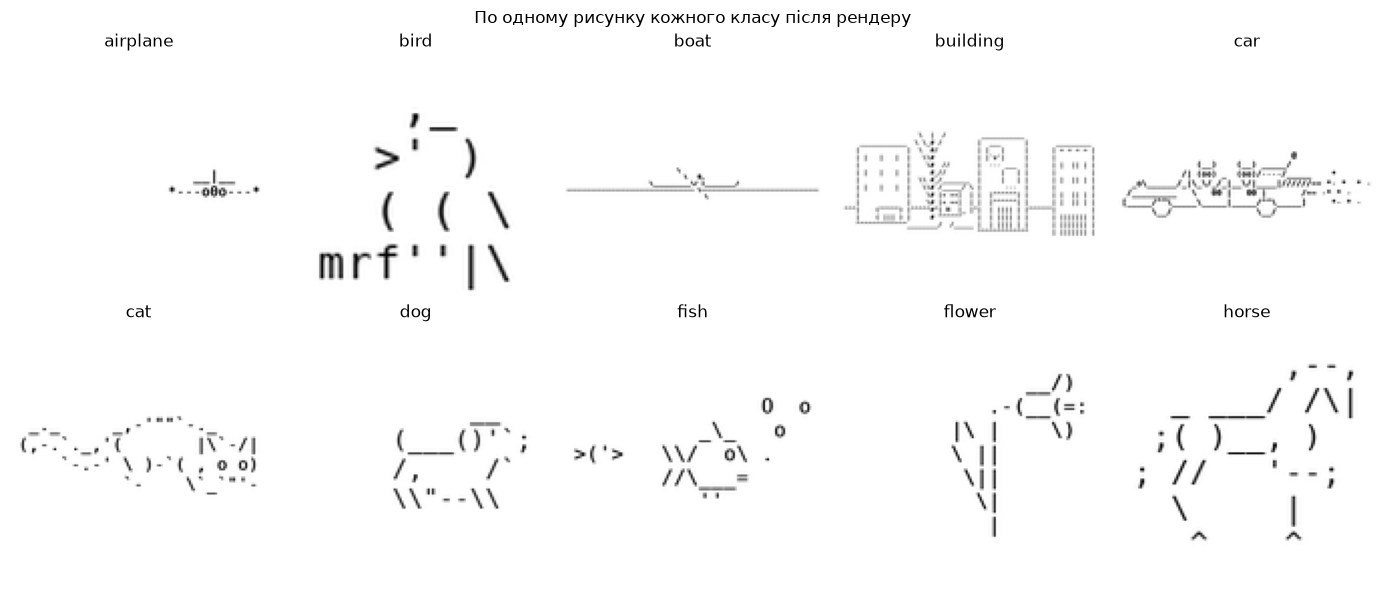

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, cls in zip(axes.flat, classes):
    i = np.flatnonzero(labels == cls)[3]
    ax.imshow(render(texts[i]), cmap='gray_r')
    ax.set_title(cls)
    ax.axis('off')
plt.suptitle('По одному рисунку кожного класу після рендеру')
plt.tight_layout()
plt.show()

## 3. Розбиття на train / validation / test

| Частина | Частка | Для чого |
|---|---|---|
| **train** | 70% | на цих прикладах модель навчається |
| **validation** | 15% | порівнюємо моделі й гіперпараметри, обираємо найкращу |
| **test** | 15% | **одноразова** фінальна оцінка обраної моделі |

Якщо обирати модель за test, ми непрямо підганяємо її під test, і фінальна оцінка стає завищеною. Тому вибір робиться тільки за validation, а test використовується один раз, у розділі 8.

Розбиття стратифіковане і з фіксованим `random_state`, тому відтворюється при кожному запуску. Воно зберігається у `splits.csv` у корені проєкту, і рівні 2 та 3 використають **ті самі** train/val/test. Тільки так порівняння трьох рівнів буде чесним.

In [6]:
indices = np.arange(len(texts))
train_idx, rest_idx = train_test_split(indices, test_size=0.3, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, stratify=labels[rest_idx], random_state=SEED)

split = np.empty(len(texts), dtype=object)
split[train_idx], split[val_idx], split[test_idx] = 'train', 'val', 'test'
splits = pd.DataFrame({'file': manifest['file'], 'label': labels, 'split': split})
splits.to_csv(SPLITS_PATH, index=False)

pd.crosstab(splits['split'], splits['label'], margins=True).loc[['train', 'val', 'test', 'All']]

label,airplane,bird,boat,building,car,cat,dog,fish,flower,horse,All
split,,,,,,,,,,,
train,72,169,64,156,66,158,85,38,73,57,938
val,15,36,14,33,14,34,18,9,15,13,201
test,16,36,13,34,15,34,18,8,16,12,202
All,103,241,91,223,95,226,121,55,104,82,1341


## 4. Ручні ознаки

Класичний класифікатор не вміє «дивитися» на рисунок — він приймає тільки **вектор чисел фіксованої довжини**. Ці числа (ознаки) ми обираємо і рахуємо самі. Використовуємо три групи:

**а) Структурні ознаки (7 чисел)** — загальна форма рисунка:
висота і ширина в символах, співвідношення сторін, щільність «чорнила» (частка непробільних символів), середня і розкид довжини рядків, кількість різних символів. Наприклад, човни й машини зазвичай широкі й низькі, а будівлі — високі.

**б) Частоти символів (95 чисел)** — яку частку рисунка складає кожен друкований символ (`/`, `\`, `|`, `_`, `~`, `o`, ...) плюс частка «інших» символів. Ідея: у рибах багато `~` і `<>`, у будівлях — `|`, `_`, `[]`.

**в) HOG — Histogram of Oriented Gradients (1764 числа)** — класичний дескриптор форми зображення:
1. зображення ділиться на клітинки 16×16 пікселів;
2. у кожній клітинці рахується, в яких напрямках ідуть лінії (9 напрямків від 0° до 180°);
3. сусідні клітинки групуються в блоки 2×2 і нормалізуються, щоб ознаки не залежали від товщини ліній.

HOG описує, *де* на рисунку вертикальні, горизонтальні й похилі краї, тобто його силует.
Розмір клітинки 16×16 обрано за попереднім порівнянням з 8×8 і з іншими розмірами зображення: 8×8 дає 8100 ознак на ~940 навчальних прикладів, і моделі сильніше перенавчаються.

In [7]:
PRINTABLE = string.printable[:94]


def structural_features(text):
    lines = text.rstrip('\n').split('\n')
    lengths = np.array([len(line.rstrip()) for line in lines])
    height, width = len(lines), lengths.max()
    ink = sum(1 for ch in text if not ch.isspace())
    return [
        height,
        width,
        width / height,
        ink / (height * width),
        lengths.mean() / width,
        lengths.std() / width,
        len(set(text) - set(' \n')),
    ]


def char_features(text):
    ink = [ch for ch in text if not ch.isspace()]
    frequencies = [ink.count(ch) / len(ink) for ch in PRINTABLE]
    other = sum(1 for ch in ink if ch not in PRINTABLE) / len(ink)
    return frequencies + [other]


def hog_features(image):
    return hog(image, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))


def extract_features(texts):
    return {
        'structural': np.array([structural_features(t) for t in texts]),
        'chars': np.array([char_features(t) for t in texts]),
        'hog': np.array([hog_features(render(t)) for t in texts]),
    }

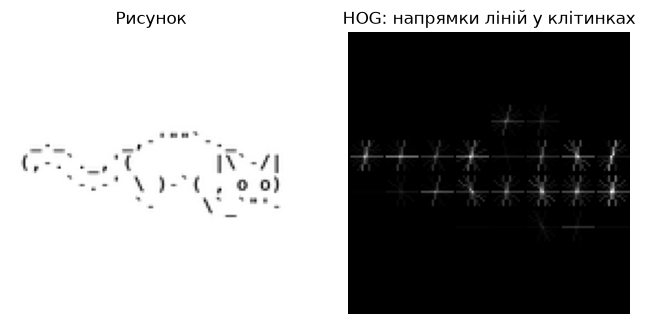

In [8]:
example = render(texts[np.flatnonzero(labels == 'cat')[3]])
_, hog_image = hog(example, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example, cmap='gray_r')
axes[0].set_title('Рисунок')
axes[1].imshow(hog_image, cmap='gray')
axes[1].set_title('HOG: напрямки ліній у клітинках')
for ax in axes:
    ax.axis('off')
plt.show()

## 5. Вимірювання часу і пам'яті

Для кожного етапу міряємо:
- **час** — `time.perf_counter()` до і після;
- **пікову RAM** — окремий потік кожні 5 мс зчитує, скільки оперативної пам'яті займає процес (RSS, через `psutil`), і запам'ятовує максимум. Це пік усього процесу, разом з Python, Jupyter і завантаженими даними: процес не повертає зайняту пам'ять системі, тому приріст окремого етапу виміряти надійно не можна, а загальний пік — можна.
- **VRAM** не використовується: усі методи рівня 1 працюють на CPU.

Що вважаємо часом навчання та інференсу:
- **навчання** = вилучення ознак з train + навчання моделі (`fit`);
- **інференс** = вилучення ознак з test + передбачення (`predict`). Новий рисунок теж спочатку треба перетворити на ознаки, тому цей етап входить у вартість.

In [9]:
class Measure:
    def __enter__(self):
        self.process = psutil.Process()
        self.peak_rss = self.process.memory_info().rss
        self.running = True
        self.sampler = threading.Thread(target=self.sample, daemon=True)
        self.sampler.start()
        self.started = time.perf_counter()
        return self

    def sample(self):
        while self.running:
            self.peak_rss = max(self.peak_rss, self.process.memory_info().rss)
            time.sleep(0.005)

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.started
        self.running = False
        self.sampler.join()
        self.peak_rss = max(self.peak_rss, self.process.memory_info().rss)
        self.peak_mb = self.peak_rss / 2**20

In [10]:
features, feature_cost = {}, {}
for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    with Measure() as m:
        features[name] = extract_features([texts[i] for i in idx])
    feature_cost[name] = m
    print(f'{name:5}: {len(idx):4} рисунків, {m.seconds:5.2f} с, пік RAM {m.peak_mb:.0f} MB')

y_train, y_val, y_test = labels[train_idx], labels[val_idx], labels[test_idx]
{group: matrix.shape[1] for group, matrix in features['train'].items()}

train:  938 рисунків,  7.21 с, пік RAM 216 MB
val  :  201 рисунків,  1.11 с, пік RAM 218 MB
test :  202 рисунків,  0.93 с, пік RAM 220 MB


{'structural': 7, 'chars': 95, 'hog': 1764}

## 6. Моделі та підбір гіперпараметрів

Порівнюємо три класичні класифікатори:

- **Logistic Regression** — проводить лінійні межі між класами; найпростіша і найшвидша модель.
- **SVM (`SVC`, ядро RBF)** — шукає межі між класами з максимальним «зазором»; RBF-ядро дозволяє межам бути криволінійними.
- **Random Forest** — сотні дерев рішень, кожне вчиться на випадковій підвибірці прикладів і ознак; відповідь — голосування дерев.

Для LR і SVM ознаки спочатку стандартизуються (`StandardScaler`: середнє 0, стандартне відхилення 1). Без цього ознака «висота в рядках» (десятки) переважала б частоти символів (соті частки). Random Forest до масштабу нечутливий.

**Гіперпараметри** — налаштування, які задаються до навчання:
- `C` у LR і SVM — наскільки сильно модель намагається не помилятися на train (більше `C` = складніші межі = вищий ризик перенавчання);
- `max_features` і `min_samples_leaf` у Random Forest — скільки ознак бачить кожне розбиття дерева і скільки мінімум прикладів у листі.

Кожну конфігурацію навчаємо на train, оцінюємо на validation і обираємо найкращу за **macro-F1**. Macro-F1 на train показуємо поруч, щоб бачити перенавчання.

In [11]:
def combine(groups, names=('structural', 'chars', 'hog')):
    return np.hstack([groups[name] for name in names])


X_train, X_val, X_test = combine(features['train']), combine(features['val']), combine(features['test'])


def logistic_regression(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=5000))


def svm(C):
    return make_pipeline(StandardScaler(), SVC(C=C, class_weight='balanced'))


def random_forest(max_features, min_samples_leaf):
    return RandomForestClassifier(
        n_estimators=500,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1,
    )


candidates = {}
for C in [0.001, 0.01, 0.1]:
    candidates[f'LogReg C={C}'] = lambda C=C: logistic_regression(C)
for C in [0.3, 1, 3, 10]:
    candidates[f'SVM C={C}'] = lambda C=C: svm(C)
for max_features in ['sqrt', 0.05]:
    for min_samples_leaf in [1, 3]:
        candidates[f'RF max_features={max_features} min_leaf={min_samples_leaf}'] = (
            lambda mf=max_features, msl=min_samples_leaf: random_forest(mf, msl)
        )

rows = []
for name, build in candidates.items():
    model = build().fit(X_train, y_train)
    val_pred = model.predict(X_val)
    rows.append({
        'модель': name,
        'train macro-F1': f1_score(y_train, model.predict(X_train), average='macro'),
        'val macro-F1': f1_score(y_val, val_pred, average='macro'),
        'val accuracy': accuracy_score(y_val, val_pred),
    })

selection = pd.DataFrame(rows).sort_values('val macro-F1', ascending=False).reset_index(drop=True)
best_name = selection.loc[0, 'модель']
print('Найкраща конфігурація на validation:', best_name)
selection.round(3)

Найкраща конфігурація на validation: RF max_features=0.05 min_leaf=3


,модель,train macro-F1,val macro-F1,val accuracy
0,RF max_features=0.05 min_leaf=3,0.998,0.485,0.483
1,RF max_features=0.05 min_leaf=1,1.000,0.474,0.483
2,LogReg C=0.01,0.994,0.469,0.493
3,SVM C=1,0.933,0.467,0.478
4,LogReg C=0.1,1.000,0.464,0.488
5,SVM C=10,1.000,0.460,0.488
6,RF max_features=sqrt min_leaf=3,0.997,0.452,0.453
7,SVM C=3,1.000,0.447,0.478
8,RF max_features=sqrt min_leaf=1,1.000,0.445,0.458
9,LogReg C=0.001,0.779,0.429,0.443


## 7. Внесок кожної групи ознак

Щоб зрозуміти, які ознаки реально допомагають, навчаємо обрану конфігурацію на кожній групі окремо і на всіх разом (оцінка на validation).

In [12]:
groups = {
    'тільки структурні': ('structural',),
    'тільки частоти символів': ('chars',),
    'тільки HOG': ('hog',),
    'структурні + символи': ('structural', 'chars'),
    'усі ознаки': ('structural', 'chars', 'hog'),
}

ablation = []
for title, names in groups.items():
    model = candidates[best_name]().fit(combine(features['train'], names), y_train)
    pred = model.predict(combine(features['val'], names))
    ablation.append({
        'ознаки': title,
        'кількість ознак': combine(features['train'], names).shape[1],
        'val macro-F1': f1_score(y_val, pred, average='macro'),
        'val accuracy': accuracy_score(y_val, pred),
    })
pd.DataFrame(ablation).round(3)

,ознаки,кількість ознак,val macro-F1,val accuracy
0,тільки структурні,7,0.289,0.294
1,тільки частоти символів,95,0.424,0.453
2,тільки HOG,1764,0.452,0.453
3,структурні + символи,102,0.488,0.507
4,усі ознаки,1866,0.485,0.483


## 8. Фінальна модель: навчання і оцінка на test

Навчаємо обрану конфігурацію на train ще раз — уже з вимірюванням часу і пам'яті — і **один раз** оцінюємо на test.

In [13]:
with Measure() as fit_cost:
    final_model = candidates[best_name]().fit(X_train, y_train)

with Measure() as predict_cost:
    test_pred = final_model.predict(X_test)

train_seconds = feature_cost['train'].seconds + fit_cost.seconds
inference_seconds = feature_cost['test'].seconds + predict_cost.seconds

test_accuracy = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average='macro')
test_weighted_f1 = f1_score(y_test, test_pred, average='weighted')

print(f'Модель: {best_name}')
print(f'Test accuracy:    {test_accuracy:.3f}')
print(f'Test macro-F1:    {test_macro_f1:.3f}')
print(f'Test weighted-F1: {test_weighted_f1:.3f}')
print()
print(classification_report(y_test, test_pred, digits=3))

Модель: RF max_features=0.05 min_leaf=3
Test accuracy:    0.515
Test macro-F1:    0.525
Test weighted-F1: 0.510

              precision    recall  f1-score   support

    airplane      0.579     0.688     0.629        16
        bird      0.409     0.500     0.450        36
        boat      0.500     0.615     0.552        13
    building      0.720     0.529     0.610        34
         car      0.407     0.733     0.524        15
         cat      0.611     0.324     0.423        34
         dog      0.417     0.278     0.333        18
        fish      0.500     0.625     0.556         8
      flower      0.500     0.562     0.529        16
       horse      0.615     0.667     0.640        12

    accuracy                          0.515       202
   macro avg      0.526     0.552     0.525       202
weighted avg      0.538     0.515     0.510       202



**Як читати звіт:**
- **precision** — з усіх рисунків, які модель назвала цим класом, яка частка справді цього класу;
- **recall** — з усіх рисунків цього класу, яку частку модель знайшла;
- **f1-score** — середнє гармонійне precision і recall;
- **support** — скільки рисунків цього класу в test.

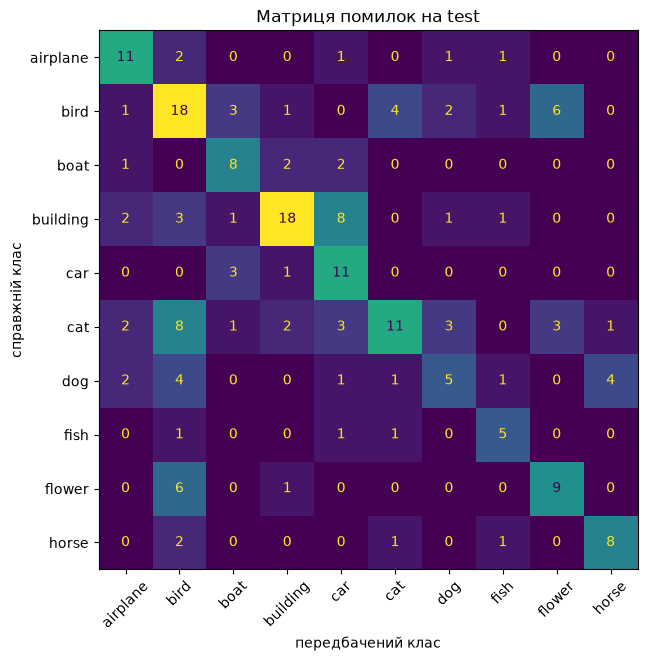

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=classes, xticks_rotation=45, colorbar=False, ax=ax)
ax.set_title('Матриця помилок на test')
ax.set_xlabel('передбачений клас')
ax.set_ylabel('справжній клас')
plt.show()

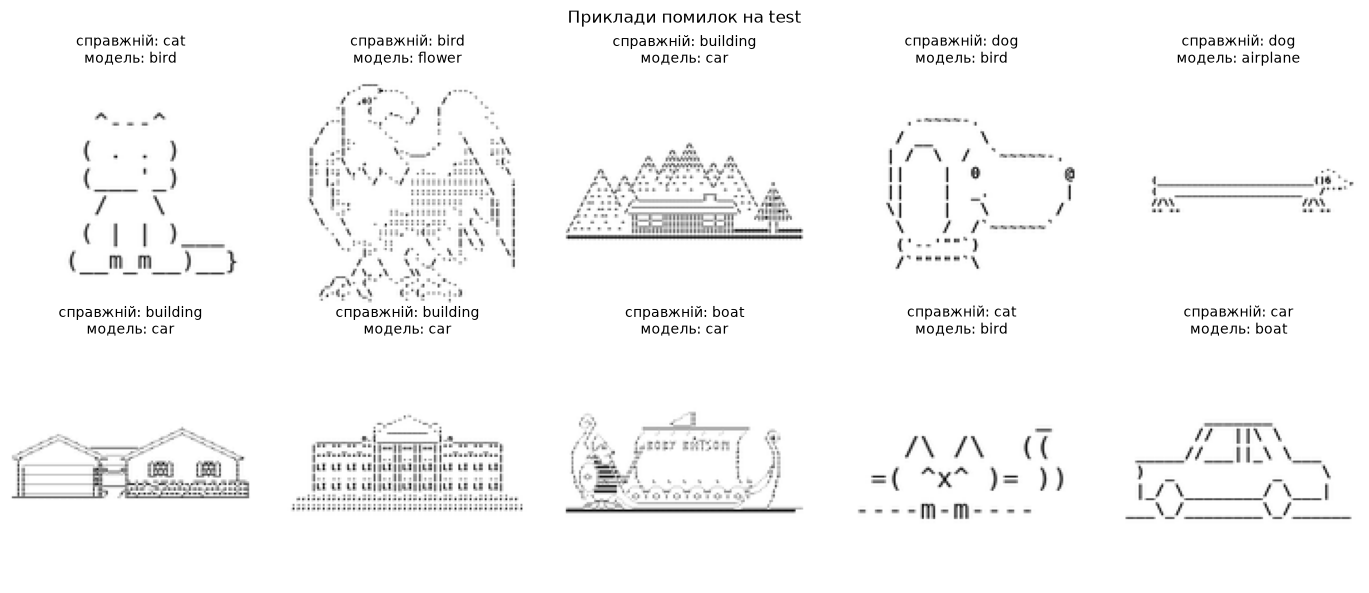

In [15]:
wrong = np.flatnonzero(test_pred != y_test)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flat, wrong[:10]):
    ax.imshow(render(texts[test_idx[i]]), cmap='gray_r')
    ax.set_title(f'справжній: {y_test[i]}\nмодель: {test_pred[i]}', fontsize=10)
    ax.axis('off')
plt.suptitle('Приклади помилок на test')
plt.tight_layout()
plt.show()

## 9. Зведення результатів

Результати зберігаються у `results.json` — вони знадобляться для порівняльної таблиці трьох рівнів у фінальному ноутбуці.

In [ ]:
results = {
    'level': 1,
    'method': f'Ручні ознаки (структурні + символи + HOG) + {best_name}',
    'test_accuracy': round(test_accuracy, 4),
    'test_macro_f1': round(test_macro_f1, 4),
    'train_seconds': round(train_seconds, 3),
    'inference_seconds': round(inference_seconds, 3),
    'inference_ms_per_sample': round(1000 * inference_seconds / len(test_idx), 3),
    'peak_ram_mb': round(max(m.peak_mb for m in [*feature_cost.values(), fit_cost, predict_cost])),
    'peak_vram_mb': None,
}
with open('results.json', 'w') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

pd.DataFrame([
    ['Метрика на test: accuracy', f'{test_accuracy:.3f}'],
    ['Метрика на test: macro-F1', f'{test_macro_f1:.3f}'],
    ['Час навчання: ознаки train', f"{feature_cost['train'].seconds:.2f} с"],
    ['Час навчання: fit', f'{fit_cost.seconds:.2f} с'],
    ['Час навчання: разом', f'{train_seconds:.2f} с'],
    ['Час інференсу: ознаки test', f"{feature_cost['test'].seconds:.2f} с"],
    ['Час інференсу: predict', f'{predict_cost.seconds:.3f} с'],
    ['Час інференсу: разом', f'{inference_seconds:.2f} с ({results["inference_ms_per_sample"]:.1f} мс на рисунок)'],
    ['Пікова RAM процесу', f"{results['peak_ram_mb']} MB"],
    ['VRAM', 'не використовується (CPU)'],
], columns=['Показник', 'Значення'])

,Показник,Значення
0,Метрика на test: accuracy,0.515
1,Метрика на test: macro-F1,0.525
2,Час навчання: ознаки train,7.21 с
3,Час навчання: fit,1.99 с
4,Час навчання: разом,9.20 с
5,Час інференсу: ознаки test,0.93 с
6,Час інференсу: predict,0.112 с
7,Час інференсу: разом,1.04 с (5.2 мс на рисунок)
8,Пікова RAM процесу,329 MB
9,VRAM,не використовується (CPU)


## 10. Висновки

**Результат.** Найкраща конфігурація рівня 1 — Random Forest (500 дерев, `max_features=0.05`, `min_samples_leaf=3`) на всіх ручних ознаках. На test: **accuracy ≈ 0.52, macro-F1 ≈ 0.53**. Випадкове вгадування серед 10 класів дало б ≈ 0.10, тож ручні ознаки несуть корисну інформацію, але приблизно половина рисунків класифікується неправильно.

**Порівняння моделей.** Найкращі конфігурації LogReg, SVM і Random Forest відрізняються на validation лише на 1–3 п.п. macro-F1 (0.47–0.49). Validation містить лише 201 рисунок, тому така різниця частково випадкова. З тієї ж причини test-оцінка (0.53) трохи вища за validation (0.49), і це не означає, що модель «стала кращою». Головне обмеження тут — ознаки, а не вибір класифікатора.

**Перенавчання.** Майже всі моделі мають macro-F1 ≈ 1.0 на train і ≈ 0.5 на validation: вони запам'ятовують навчальні рисунки, але погано узагальнюють. Сильніша регуляризація (мале `C`, більший `min_samples_leaf`) зменшує розрив, але не підвищує якість на validation. Отже, проблема не лише в перенавчанні: ручним ознакам бракує інформації, щоб розрізнити схожі класи.

**Внесок ознак.** Структурні ознаки самі по собі слабкі (≈ 0.29), частоти символів (≈ 0.42) і HOG (≈ 0.45) кращі. Структурні + символи (102 ознаки) дають стільки ж, скільки всі ознаки разом (≈ 0.49): HOG поверх них майже нічого не додає. Класичний дескриптор форми описує напрямки ліній, але не вловлює деталей, які відрізняють, наприклад, кота від собаки.

**Помилки.** Модель спирається на загальний силует і набір символів:
- широкі низькі будівлі плутає з машинами, човни — з машинами;
- тварини плутаються між собою найбільше: recall для cat ≈ 0.32, для dog ≈ 0.28, їх часто називає bird;
- найкраще розпізнаються класи з характерною формою: airplane, horse, building, fish.

**Вартість.** Метод дуже дешевий: навчання займає лічені секунди на CPU (у різних запусках ≈ 6–10 с, більшу частину — рендер і вилучення ознак; значення останнього запуску — у таблиці розділу 9), інференс ≈ 5 мс на рисунок, пікова RAM процесу ≈ 330 MB (здебільшого сам Python і Jupyter), GPU не потрібен.

**Що далі.** На рівні 2 згорткова нейромережа (CNN) вчитиметься знаходити ознаки безпосередньо з пікселів, замість того щоб ми задавали їх вручну. Очікуємо, що вона краще розрізнятиме дрібні деталі, які відрізняють тварин. Порівнювати будемо на тому самому test з `splits.csv`.